# SDC3b posteriors: worked example

This notebook shows how to load the SDC3b team posteriors and make the kinds of figures shown in the SDC3b paper:

1. the input reionization histories and the frequency bands,
2. corner plots of the 3-D posteriors $P(x_1, x_2, x_3)$,
3. the average posterior of all teams,
4. credible intervals per band (boxplot),
5. the comparison diagnostics $Z_p$, $D_{\rm M}$ and $S_{\rm SDC3b}$.

Set `CASE` below to `'PS1'`, `'PS2'`, `'PS3'` or `'IM1'` to switch dataset. Teams are listed in the same order as in the paper.

The diagnostics each describe one aspect of how a posterior relates to the input values. They are meant to help understand the results, not to rank the teams.

## Setup

Install the dependencies once with `pip install -r analysis/requirements.txt`; `sdc3b_tools` itself needs no installation, it is imported from `analysis/`. The first run downloads the posteriors from the GitHub release into `data/posteriors/` (about 80 MB); later runs reuse them.

In [ ]:
import sys
from pathlib import Path

# Locate analysis/ from the notebook folder or anywhere inside the repository
here = Path.cwd().resolve()
ANALYSIS = next(p / 'analysis' for p in [here, *here.parents] if (p / 'analysis' / 'sdc3b_tools').is_dir())
sys.path[:0] = [str(ANALYSIS), str(ANALYSIS / 'scripts')]

import numpy as np
import matplotlib.pyplot as plt

import sdc3b_tools as st
from fetch_posteriors import fetch

fetch()

In [2]:
CASE = 'PS1'

posteriors, coords = st.load_case(CASE)
truth = st.load_truth(CASE)

print(f'{CASE}: {len(posteriors)} posteriors on a {len(coords)}^3 grid')
print('true band-centre values:', truth['centre'])
print('true ranges per band:   ', truth['ranges'])

PS1: 24 posteriors on a 100^3 grid
true band-centre values: [0.6996, 0.40125, 0.12525]
true ranges per band:    [[0.5717, 0.8275], [0.2308, 0.5717], [0.0197, 0.2308]]


## 1. Input reionization histories

$x_{\rm HI}(z)$ of the three input simulations. The shaded columns are the three frequency bands; IM1 shares the PS3 input.

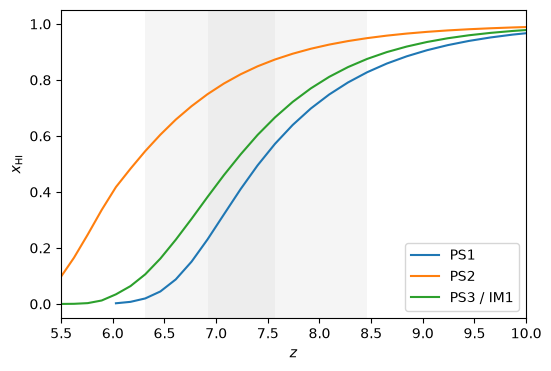

In [3]:
TRUTH_DIR = ANALYSIS.parent / 'data' / 'truth'
bands = st.io._read_yaml('truth.yml')['bands']

fig, ax = plt.subplots(figsize=(6, 4))
for k, (name, band) in enumerate(bands.items()):
    ax.axvspan(*sorted(band['z']), color='0.5', alpha=0.08 + 0.06 * (k % 2), lw=0)
for case in ['PS1', 'PS2', 'PS3']:
    z, xhi = np.loadtxt(TRUTH_DIR / f'True_xh_z_{case}.txt', unpack=True)
    ax.plot(z, xhi, label=case + (' / IM1' if case == 'PS3' else ''))
ax.set_xlim(5.5, 10)
ax.set_xlabel('$z$')
ax.set_ylabel(r'$x_{\rm HI}$')
ax.legend()
plt.show()

## 2. Corner plot

Overlay a few posteriors. With many teams the plot becomes crowded, so pick a subset; for PS3 and IM1 all teams fit.

In [4]:
names = [name for name, _ in posteriors]
print(names)

['Akashganga', 'Cantabrigians', 'COTSS-21', 'EoR PIE MC', 'EoR PIE', 'HIMALAYA', 'HIstorians ANN', 'HIstorians GPR', 'HIstorians LCDM Bayesian', 'Imperial-Nottingham', 'KUSANAGI', 'Loreli A', 'Loreli B', 'ReionYuga', 'RISE', 'Modern SEarCH', 'Traditional SEarCH', 'Shuimu-Tianlai A', 'Shuimu-Tianlai B', 'Shuimu-Tianlai C', 'ToSKA - Explicit likelihood', 'ToSKA - Model Selection', 'ToSKA - SBI general', 'YEYE']


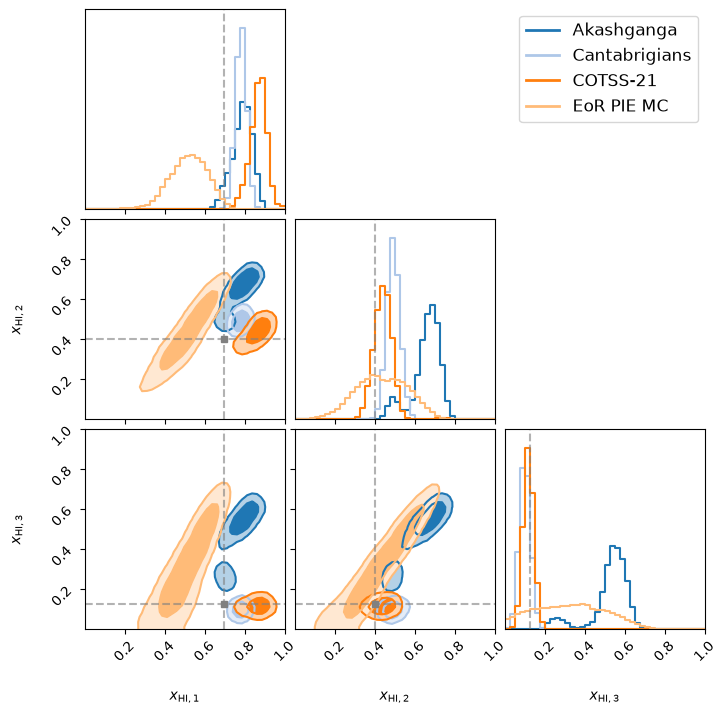

In [5]:
selected = names[:4] if len(names) > 4 else names

plotter = st.GridCornerPlotter(coords, engine='corner', true_values=truth['centre'])
for name, grid in posteriors:
    if name in selected:
        plotter.add_posterior(grid, label=name)
fig = plotter.plot_corner()
plt.show()

To save one corner plot per team (as offered for download in the paper), loop over the posteriors:

```python
out = Path('corner_plots'); out.mkdir(exist_ok=True)
for name, grid in posteriors:
    p = st.GridCornerPlotter(coords, true_values=truth['centre'])
    p.add_posterior(grid, label=name)
    p.plot_corner().savefig(out / f"{CASE}_{name.replace(' ', '_')}.png", dpi=150)
    plt.close('all')
```

## 3. Average posterior

The mean of all submitted grids. It has no meaning as a Bayesian posterior, but shows how the teams populated the parameter space.

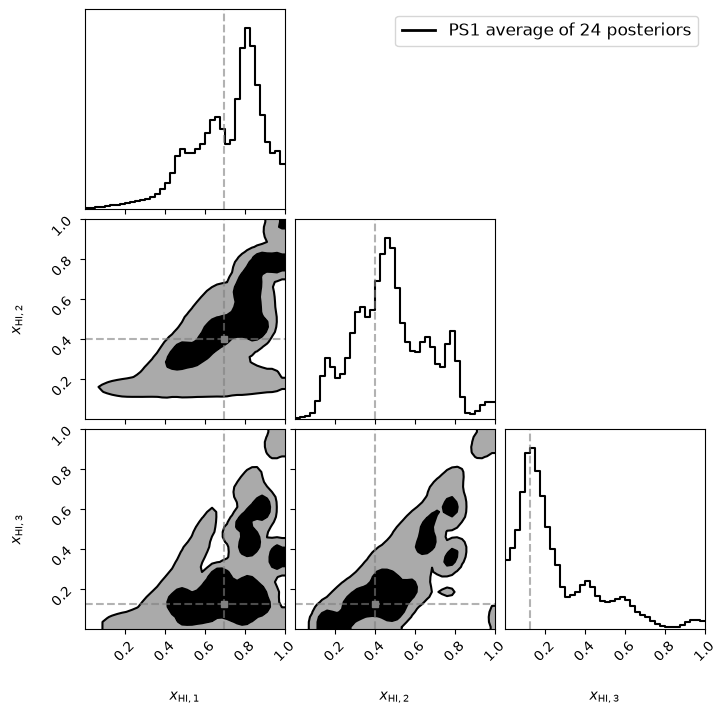

In [6]:
average = np.mean([grid for _, grid in posteriors], axis=0)

plotter = st.GridCornerPlotter(coords, engine='corner', true_values=truth['centre'])
plotter.add_posterior(average, label=f'{CASE} average of {len(posteriors)} posteriors', color='black')
fig = plotter.plot_corner()
plt.show()

## 4. Credible intervals per band

Boxes are the 68% and whiskers the 95% equal-tailed credible intervals of the 1-D marginals; markers are the marginal medians. The dashed line is the true band-centre value and the grey area the true range over the band.

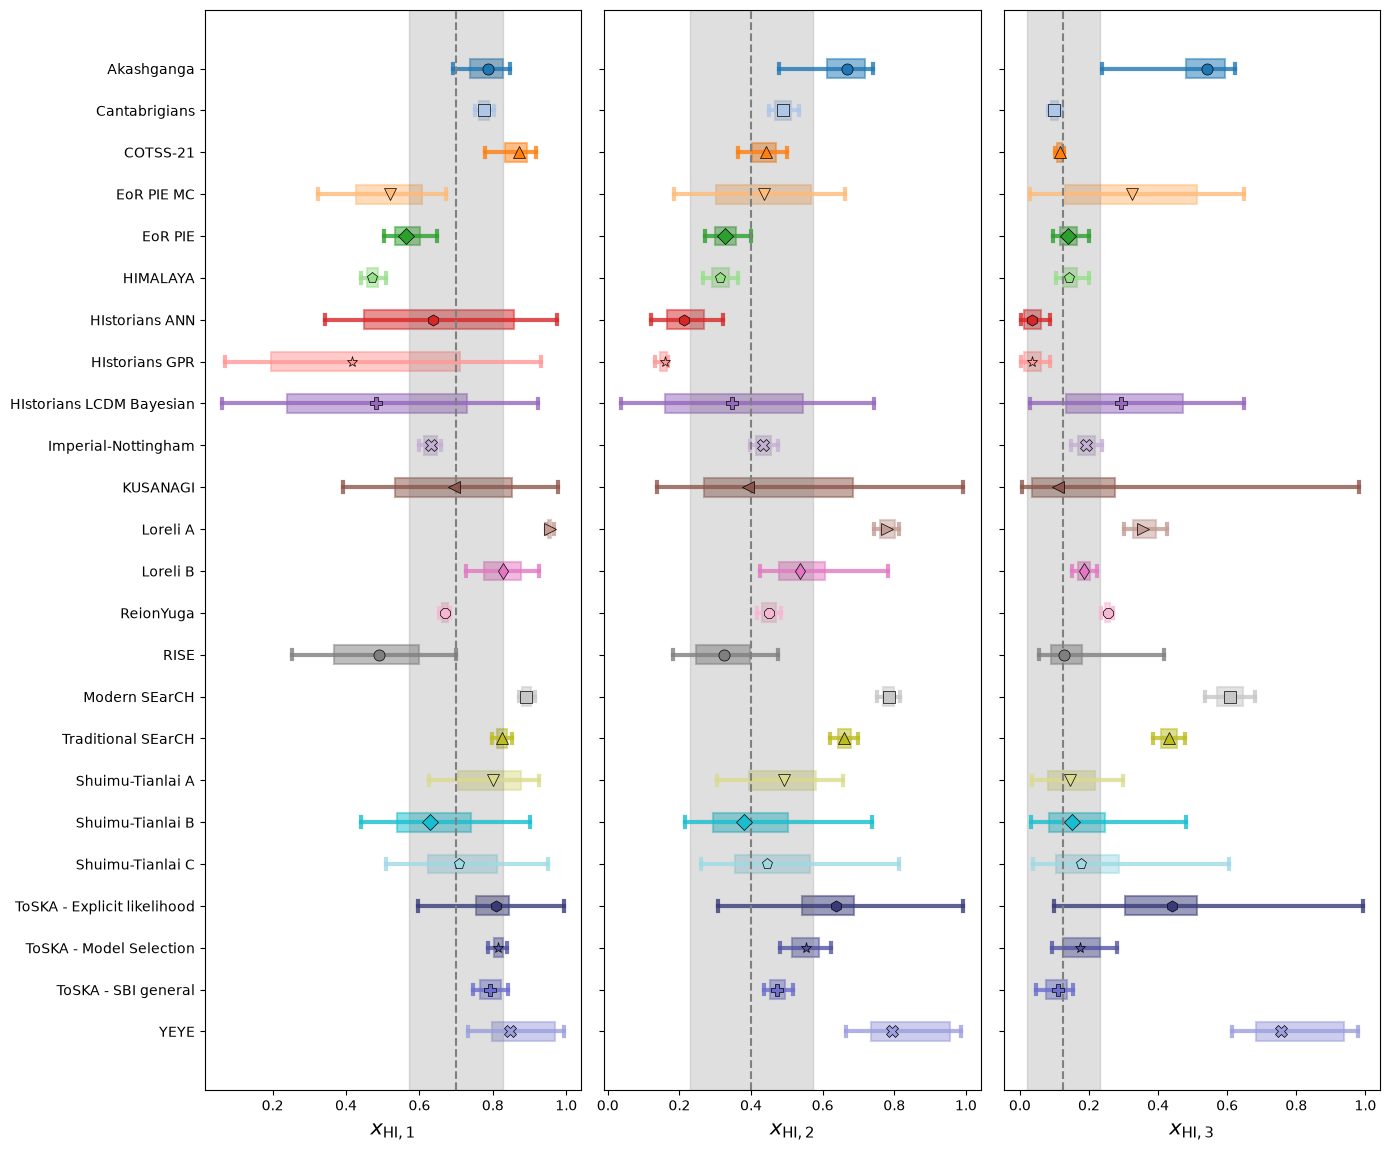

In [7]:
comp = st.ComparisonPlotter(coords, true_values=truth['centre'], true_ranges=truth['ranges'])
for name, grid in posteriors:
    comp.add_posterior(grid, label=name)

fig = comp.plot_boxplot()
plt.show()

## 5. Diagnostics

- $Z_p$: |mean − true value| / σ of the marginal in band $p$, i.e. the offset in units of the posterior width.
- $D_{\rm M}$: Mahalanobis distance of the true values from the posterior mean, using the 3×3 posterior covariance.
- $S_{\rm SDC3b}$: fraction of the posterior mass inside the cuboid spanned by the true ranges, as defined for the challenge.

In [8]:
comp.get_metrics_table()

,Team,Z_1,Z_2,Z_3,Mahalanobis,Score
0,Akashganga,1.929,3.654,4.043,7.679,0.0146
1,Cantabrigians,5.827,3.960,2.469,8.362,0.9995
2,COTSS-21,4.630,0.889,1.461,10.733,0.1495
3,EoR PIE MC,2.023,0.253,1.155,15.063,0.0004
4,EoR PIE,3.635,2.225,0.610,10.190,0.4275
5,HIMALAYA,8.943,2.354,0.656,9.845,0.0012
6,HIstorians ANN,0.289,3.623,3.884,5.319,0.1169
7,HIstorians GPR,1.080,25.530,3.884,25.846,0.0000
8,HIstorians LCDM Bayesian,0.942,0.246,1.095,1.465,0.0580
9,Imperial-Nottingham,4.159,1.675,2.811,16.536,0.9449


The same quantities can be compared pairwise, for example the bias $\bar{x} - x'$ (median minus true value) against the width $\Delta_{68}$ of the 68% interval in each band. The ideal outcome is close to (0, 0). In the grey area the bias is smaller than the error bar, $|\bar{x} - x'| < \Delta_{68}/2$; points outside it have error bars that are too small for their offset from the input.

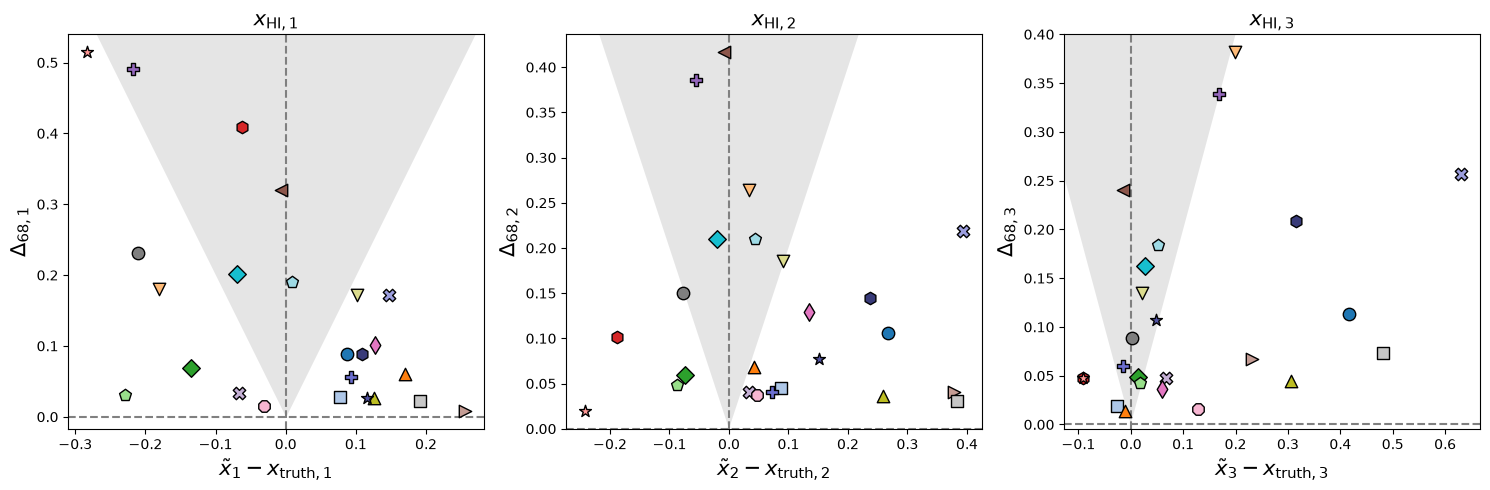

In [9]:
fig = comp.plot_metric_combinations('Bias', 'CI68')
for ax in fig.axes:
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    x = np.linspace(*xlim, 300)
    ax.fill_between(x, 2 * np.abs(x), ylim[1], color='gray', alpha=0.2, lw=0, zorder=0)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
plt.show()